In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
from pandas.api.types import is_bool_dtype, is_numeric_dtype
from sklearn.model_selection import train_test_split

sys.path.insert(0, str(Path.cwd().parent))
from ecl.donnees import charger_config, charger_features, moteur

config = charger_config()
GRAINE = config["reproductibilite"]["graine"]
CIBLE = "defaut_observe"

clients = charger_features(moteur(), "train")
clients["duree_mois"] = clients["montant_credit"] / clients["annuite"]
clients["ratio_financement"] = clients["montant_credit"] / clients["prix_bien"]

CANDIDATES = [
    "score_externe_1", "score_externe_2", "score_externe_3",
    "anciennete_emploi_annees", "type_revenu",
    "prix_bien", "montant_credit", "annuite", "duree_mois", "ratio_financement",
    "retard_paiement_max", "pct_paiements_en_retard", "taux_refus_passe",
    "age", "niveau_etudes", "note_region", "revenu_annuel",
    "nb_credits_externes_actifs", "utilisation_carte_moyenne",
]

X = clients[CANDIDATES]
y = clients[CIBLE]
X_app, X_val, y_app, y_val = train_test_split(
    X, y, test_size=config["reproductibilite"]["part_test"], stratify=y, random_state=GRAINE)

print(f"Apprentissage : {len(X_app)} clients, taux = {y_app.mean():.2%}")
print(f"Validation    : {len(X_val)} clients, taux = {y_val.mean():.2%}")

Apprentissage : 21518 clients, taux = 7.94%
Validation    : 9222 clients, taux = 7.94%


In [2]:
from optbinning import BinningProcess

def preparer(X):
    """Met les colonnes texte au format attendu par optbinning."""
    X = X.copy()
    texte = [c for c in X.columns if not is_numeric_dtype(X[c]) or is_bool_dtype(X[c])]
    X[texte] = X[texte].astype(str).astype(object)
    return X, texte

X_app_p, categorielles = preparer(X_app)
X_val_p, _ = preparer(X_val)

bp = BinningProcess(variable_names=CANDIDATES, categorical_variables=categorielles)
bp.fit(X_app_p, y_app)

iv_app = bp.summary()[["name", "n_bins", "iv"]].sort_values("iv", ascending=False).reset_index(drop=True)

X_app_woe = bp.transform(X_app_p, metric="woe")
X_val_woe = bp.transform(X_val_p, metric="woe")

display(iv_app.round(4))
X_app_woe.head()

,name,n_bins,iv
0,score_externe_2,12,0.392486
1,score_externe_3,9,0.351963
2,duree_mois,5,0.145924
3,score_externe_1,5,0.123803
4,prix_bien,11,0.115921
5,anciennete_emploi_annees,8,0.103643
6,retard_paiement_max,4,0.093217
7,taux_refus_passe,4,0.090922
8,pct_paiements_en_retard,5,0.08514
9,montant_credit,11,0.083055


,score_externe_1,score_externe_2,score_externe_3,anciennete_emploi_annees,type_revenu,prix_bien,montant_credit,annuite,duree_mois,ratio_financement,retard_paiement_max,pct_paiements_en_retard,taux_refus_passe,age,niveau_etudes,note_region,revenu_annuel,nb_credits_externes_actifs,utilisation_carte_moyenne
15924,0.000000,0.097437,0.070204,0.075001,-0.193469,0.40836,0.339616,-0.054620,0.197600,0.166662,0.211862,0.216945,-0.316907,-0.173965,-0.123913,0.035568,-0.033934,0.009238,0.388662
26357,0.000000,0.493049,0.835900,-0.355843,0.088601,0.05892,-0.496573,-0.054620,0.197600,0.198436,0.211862,0.216945,0.152907,-0.060512,-0.123913,0.035568,-0.051072,0.090710,0.388662
7724,-0.173291,0.232535,-0.640567,0.239561,-0.193469,-0.04124,0.114721,0.007073,-0.122057,0.198436,0.211862,0.216945,-0.245473,-0.176853,-0.123913,0.035568,-0.199158,0.090710,0.388662
8648,0.000000,1.341509,0.000000,0.694178,0.605059,-0.04124,-0.090709,0.515689,0.197600,-0.195904,0.211862,0.216945,0.152907,0.430276,0.493413,0.035568,-0.033934,0.090710,0.388662
16210,-0.173291,1.341509,1.104241,-0.205351,-0.193469,0.05892,-0.220594,-0.054620,0.557012,0.198436,0.211862,0.216945,0.152907,-0.335127,0.493413,0.593378,0.176004,0.090710,0.000000


In [3]:
for col in ["score_externe_1", "score_externe_3", "anciennete_emploi_annees"]:
    vides = X_app[col].isna()
    table = bp.get_binned_variable(col).binning_table.build()
    woe_missing = table.loc[table["Bin"] == "Missing", "WoE"].iloc[0]
    print(f"{col:28} manquants : {vides.mean():5.1%}   "
          f"WoE appliqué : {X_app_woe.loc[vides, col].unique()}   "
          f"WoE de la classe Missing : {woe_missing:.4f}")

score_externe_1              manquants : 56.2%   WoE appliqué : [0.]   WoE de la classe Missing : -0.0403
score_externe_3              manquants : 19.9%   WoE appliqué : [0.]   WoE de la classe Missing : -0.1803
anciennete_emploi_annees     manquants : 18.3%   WoE appliqué : [0.]   WoE de la classe Missing : 0.3627


In [4]:
X_app_woe = bp.transform(X_app_p, metric="woe", metric_missing="empirical")
X_val_woe = bp.transform(X_val_p, metric="woe", metric_missing="empirical")

for col in ["score_externe_1", "score_externe_3", "anciennete_emploi_annees"]:
    vides = X_app[col].isna()
    print(f"{col:28} WoE appliqué aux manquants : {X_app_woe.loc[vides, col].unique()}")

score_externe_1              WoE appliqué aux manquants : [-0.04027836]
score_externe_3              WoE appliqué aux manquants : [-0.18034127]
anciennete_emploi_annees     WoE appliqué aux manquants : [0.36273421]


In [5]:
regles = config["scorecard"]
iv = iv_app.set_index("name")["iv"]
correlations = X_app_woe.corr()

gardees, decisions = [], []
for var in iv.sort_values(ascending=False).index:
    if iv[var] < regles["iv_min"]:
        decisions.append((var, round(iv[var], 4), "écartée : IV trop faible"))
        continue
    liees = [g for g in gardees if abs(correlations.loc[var, g]) > regles["correlation_max"]]
    if liees:
        r = correlations.loc[var, liees[0]]
        decisions.append((var, round(iv[var], 4), f"écartée : corrélée à {liees[0]} ({r:.2f})"))
        continue
    gardees.append(var)
    decisions.append((var, round(iv[var], 4), "gardée"))

print(f"{len(gardees)} variables gardées")
pd.DataFrame(decisions, columns=["variable", "iv", "décision"])

16 variables gardées


,variable,iv,décision
0,score_externe_2,0.3925,gardée
1,score_externe_3,0.3520,gardée
2,duree_mois,0.1459,gardée
3,score_externe_1,0.1238,gardée
4,prix_bien,0.1159,gardée
5,anciennete_emploi_annees,0.1036,gardée
6,retard_paiement_max,0.0932,gardée
7,taux_refus_passe,0.0909,gardée
8,pct_paiements_en_retard,0.0851,écartée : corrélée à retard_paiement_max (0.87)
9,montant_credit,0.0831,écartée : corrélée à prix_bien (0.82)


In [6]:
%pip install statsmodels


  Obtaining dependency information for statsmodels from https://files.pythonhosted.org/packages/b8/be/77c4b5d3f61eab5676981d20f705acee8222ad31de8aca42a331dcd4cfdb/statsmodels-0.15.0-cp311-cp311-win_amd64.whl.metadata
  Obtaining dependency information for patsy>=0.5.6 from https://files.pythonhosted.org/packages/20/70/cd3cf5cff538323076a879edef02cce6f13f7d75e03d12f211b0a0dbd178/patsy-1.0.3-py2.py3-none-any.whl.metadata
  Obtaining dependency information for formulaic>=1.1.0 from https://files.pythonhosted.org/packages/fc/75/0576b03f7889ad25b5385b4f6c69e0543713425a6f193b056c9b0a2e65ce/formulaic-1.2.2-py3-none-any.whl.metadata
  Obtaining dependency information for interface-meta>=1.2.0 from https://files.pythonhosted.org/packages/a1/d3/20a61a248feb1249cd81f83ce731f0bdf5170ed96a08a298f7081cda9e90/interface_meta-2.0.1-py3-none-any.whl.metadata
  Obtaining dependency information for wrapt>=1.0 from https://files.pythonhosted.org/packages/e6/d4/ae9ca837038a7a9aadb906eeca76b42df54e299edb29f8


[notice] A new release of pip is available: 23.2.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [7]:
import statsmodels.api as sm

def ajuster(variables):
    Xa = sm.add_constant(X_app_woe[variables])
    return sm.Logit(y_app, Xa).fit(disp=0)

logit = ajuster(gardees)
resultats = pd.DataFrame({
    "coef": logit.params,
    "erreur_type": logit.bse,
    "p_valeur": logit.pvalues,
})
resultats["signe_ok"] = (resultats["coef"] < 0) | (resultats.index == "const")
resultats["significatif"] = resultats["p_valeur"] < 0.05
resultats.round(4)

,coef,erreur_type,p_valeur,signe_ok,significatif
const,-2.4524,0.0284,0.0000,True,True
score_externe_2,-0.7760,0.0455,0.0000,True,True
score_externe_3,-0.7141,0.0480,0.0000,True,True
duree_mois,-0.4538,0.0745,0.0000,True,True
score_externe_1,-0.4630,0.0816,0.0000,True,True
prix_bien,-0.3299,0.0881,0.0002,True,True
anciennete_emploi_annees,-0.4543,0.1002,0.0000,True,True
retard_paiement_max,-0.6268,0.0829,0.0000,True,True
taux_refus_passe,-0.4574,0.0849,0.0000,True,True
ratio_financement,-0.4476,0.0962,0.0000,True,True


In [8]:
retenues = gardees.copy()
trace = []
while True:
    modele = ajuster(retenues)
    coefs = modele.params.drop("const")
    pvals = modele.pvalues.drop("const")
    positifs = coefs[coefs > 0]
    if len(positifs) > 0:
        var = pvals[positifs.index].idxmax()
        raison = f"signe positif (coef = {coefs[var]:+.3f}, p = {pvals[var]:.3f})"
    elif pvals.max() > 0.05:
        var = pvals.idxmax()
        raison = f"non significative (p = {pvals[var]:.3f})"
    else:
        break
    retenues.remove(var)
    trace.append((var, raison))

print(f"{len(retenues)} variables retenues")
display(pd.DataFrame(trace, columns=["variable retirée", "raison"]))

modele_final = ajuster(retenues)
final = pd.DataFrame({"coef": modele_final.params, "p_valeur": modele_final.pvalues})
final.round(4)

14 variables retenues


,variable retirée,raison
0,age,"signe positif (coef = +0.088, p = 0.469)"
1,revenu_annuel,non significative (p = 0.486)


,coef,p_valeur
const,-2.4522,0.0000
score_externe_2,-0.7758,0.0000
score_externe_3,-0.7109,0.0000
duree_mois,-0.4515,0.0000
score_externe_1,-0.4527,0.0000
prix_bien,-0.3332,0.0001
anciennete_emploi_annees,-0.4268,0.0000
retard_paiement_max,-0.6268,0.0000
taux_refus_passe,-0.4573,0.0000
ratio_financement,-0.4500,0.0000


,apprentissage,validation,écart
AUC,0.7629,0.7390,0.0239
Gini,0.5259,0.4781,0.0478
KS,0.3986,0.3637,0.0348


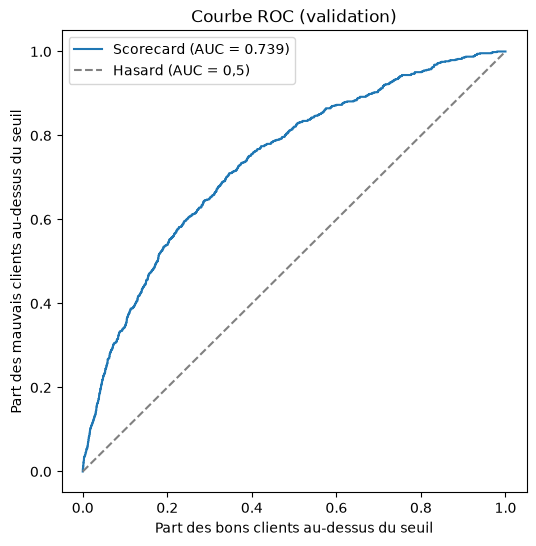

In [9]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score, roc_curve

def mesurer(y, pd_predite):
    auc = roc_auc_score(y, pd_predite)
    fpr, tpr, _ = roc_curve(y, pd_predite)
    return {"AUC": auc, "Gini": 2 * auc - 1, "KS": (tpr - fpr).max()}

pd_app = modele_final.predict(sm.add_constant(X_app_woe[retenues]))
pd_val = modele_final.predict(sm.add_constant(X_val_woe[retenues]))

perf = pd.DataFrame({"apprentissage": mesurer(y_app, pd_app), "validation": mesurer(y_val, pd_val)})
perf["écart"] = perf["apprentissage"] - perf["validation"]
display(perf.round(4))

fpr, tpr, _ = roc_curve(y_val, pd_val)
plt.figure(figsize=(6, 6))
plt.plot(fpr, tpr, label=f"Scorecard (AUC = {perf.loc['AUC', 'validation']:.3f})")
plt.plot([0, 1], [0, 1], "--", color="grey", label="Hasard (AUC = 0,5)")
plt.xlabel("Part des bons clients au-dessus du seuil")
plt.ylabel("Part des mauvais clients au-dessus du seuil")
plt.title("Courbe ROC (validation)")
plt.legend()
plt.show()

In [10]:
from sklearn.model_selection import StratifiedKFold

plis = StratifiedKFold(n_splits=config["reproductibilite"]["nb_plis"], shuffle=True, random_state=GRAINE)
cat_retenues = [c for c in categorielles if c in retenues]
resultats_cv = []

for k, (i_app, i_mes) in enumerate(plis.split(X_app_p, y_app), start=1):
    X_k_app, X_k_mes = X_app_p.iloc[i_app][retenues], X_app_p.iloc[i_mes][retenues]
    y_k_app, y_k_mes = y_app.iloc[i_app], y_app.iloc[i_mes]

    bp_k = BinningProcess(variable_names=retenues, categorical_variables=cat_retenues)
    bp_k.fit(X_k_app, y_k_app)
    w_app = bp_k.transform(X_k_app, metric="woe", metric_missing="empirical")
    w_mes = bp_k.transform(X_k_mes, metric="woe", metric_missing="empirical")

    m = sm.Logit(y_k_app, sm.add_constant(w_app, has_constant="add")).fit(disp=0)
    p = m.predict(sm.add_constant(w_mes, has_constant="add"))
    resultats_cv.append({
        "pli": k,
        "AUC": roc_auc_score(y_k_mes, p),
        "coefs_positifs": int((m.params.drop("const") > 0).sum()),
    })

cv = pd.DataFrame(resultats_cv)
display(cv.round(4))
print(f"AUC moyenne : {cv['AUC'].mean():.4f}   écart-type : {cv['AUC'].std():.4f}")

,pli,AUC,coefs_positifs
0,1,0.7410,0
1,2,0.7609,0
2,3,0.7532,0
3,4,0.7599,0
4,5,0.7389,0


AUC moyenne : 0.7508   écart-type : 0.0104


In [11]:
import math

echelle = config["scorecard"]
facteur = echelle["pdo"] / math.log(2)
offset = echelle["points_reference"] - facteur * math.log(echelle["cote_reference"])
b0 = modele_final.params["const"]
n = len(retenues)
print(f"facteur = {facteur:.2f}   offset = {offset:.1f}")

lignes = []
for var in retenues:
    table = bp.get_binned_variable(var).binning_table.build()
    table = table[(table.index != "Totals") & (table["Count"] > 0)]
    b = modele_final.params[var]
    for _, ligne in table.iterrows():
        points = -(b * ligne["WoE"] + b0 / n) * facteur + offset / n
        lignes.append({"variable": var, "classe": str(ligne["Bin"]), "clients": int(ligne["Count"]),
                       "taux_difficulte": ligne["Event rate"], "woe": ligne["WoE"], "points": points})

grille = pd.DataFrame(lignes)
grille["points"] = grille["points"].round(0).astype(int)
grille[grille["variable"] == "score_externe_2"]

facteur = 28.85   offset = 487.1


,variable,classe,clients,taux_difficulte,woe,points
0,score_externe_2,"(-inf, 0.13)",1076,0.210967,-1.131119,15
1,score_externe_2,"[0.13, 0.22)",1113,0.175202,-0.901030,20
2,score_externe_2,"[0.22, 0.28)",1151,0.124240,-0.497349,29
3,score_externe_2,"[0.28, 0.35)",1128,0.113475,-0.394503,31
4,score_externe_2,"[0.35, 0.40)",1139,0.107989,-0.338784,32
5,score_externe_2,"[0.40, 0.46)",1376,0.097384,-0.223590,35
6,score_externe_2,"[0.46, 0.54)",2783,0.072584,0.097437,42
7,score_externe_2,"[0.54, 0.63)",4422,0.063998,0.232535,45
8,score_externe_2,"[0.63, 0.68)",2717,0.050055,0.493049,51
9,score_externe_2,"[0.68, 0.71)",1830,0.037158,0.804469,58


In [12]:
z_val = sm.add_constant(X_val_woe[retenues]) @ modele_final.params
score_formule = offset - facteur * z_val

points_par_variable = [-(modele_final.params[v] * X_val_woe[v] + b0 / n) * facteur + offset / n for v in retenues]
score_grille = sum(points_par_variable)

print(f"Écart maximal entre grille et formule : {(score_grille - score_formule).abs().max():.10f}")
print(f"Score moyen en validation : {score_formule.mean():.1f}")
print(f"Min : {score_formule.min():.0f}   Max : {score_formule.max():.0f}")


Écart maximal entre grille et formule : 0.0000000000
Score moyen en validation : 570.5
Min : 469   Max : 671


In [13]:
import json

import joblib
import mlflow

DS = Path.cwd().parent
mlflow.set_tracking_uri(f"sqlite:///{(DS / 'mlflow.db').as_posix()}")
if mlflow.get_experiment_by_name("pd_scorecard") is None:
    mlflow.create_experiment("pd_scorecard", artifact_location=(DS / "mlruns").as_uri())
mlflow.set_experiment("pd_scorecard")

dossier = DS / "artefacts_tmp"
dossier.mkdir(exist_ok=True)
grille.to_csv(dossier / "grille_score.csv", index=False)
pd.DataFrame(decisions, columns=["variable", "iv", "décision"]).to_csv(dossier / "selection_variables.csv", index=False)
pd.DataFrame(trace, columns=["variable retirée", "raison"]).to_csv(dossier / "elimination.csv", index=False)
joblib.dump(bp, dossier / "decoupage_classes.joblib")
(dossier / "coefficients.json").write_text(json.dumps(modele_final.params.to_dict(), indent=2))

fpr, tpr, _ = roc_curve(y_val, pd_val)
plt.figure(figsize=(6, 6))
plt.plot(fpr, tpr, label=f"Scorecard (AUC = {perf.loc['AUC', 'validation']:.3f})")
plt.plot([0, 1], [0, 1], "--", color="grey")
plt.legend()
plt.savefig(dossier / "courbe_roc.png", dpi=120)
plt.close()

with mlflow.start_run(run_name="scorecard_v1"):
    mlflow.log_params({
        "variables": ",".join(retenues), "nb_variables": len(retenues),
        "graine": GRAINE, "part_validation": config["reproductibilite"]["part_test"],
        "pdo": echelle["pdo"], "points_reference": echelle["points_reference"],
        "cote_reference": echelle["cote_reference"], "metric_missing": "empirical",
    })
    mlflow.log_metrics({
        "auc_apprentissage": perf.loc["AUC", "apprentissage"], "auc_validation": perf.loc["AUC", "validation"],
        "gini_validation": perf.loc["Gini", "validation"], "ks_validation": perf.loc["KS", "validation"],
        "ecart_auc": perf.loc["AUC", "écart"],
        "auc_cv_moyenne": cv["AUC"].mean(), "auc_cv_ecart_type": cv["AUC"].std(),
    })
    mlflow.log_artifacts(str(dossier))
    print("Run enregistrée :", mlflow.active_run().info.run_id)

2026/10/19 19:26:44 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/10/19 19:26:44 INFO mlflow.store.db.utils: Updating database tables


Run enregistrée : f4bdefc5019e44b090b2d525873e6950
